In [8]:
# --- autoreload: keep the kernel in sync with src/ edits ---
# Python caches modules in sys.modules on first import. Without autoreload, editing
# src/data_loader.py has NO effect until the kernel is restarted, which would wipe
# every loaded image array from memory. autoreload re-imports changed modules before
# each cell runs, so the loader can be iterated on while large data stays in RAM.
%load_ext autoreload
%autoreload 2  
# mode 2 = reload all modules except those on the exclude list

# --- sys.path: make the project root importable from notebooks/ ---
# The kernel's working directory is notebooks/, so Python searches there for imports
# and cannot see ../src. Appending '..' puts the project root on the module search
# path, enabling `from src.data_loader import load_sample` without installing the
# project as a package or hardcoding absolute paths (which would break portability).
import sys
sys.path.append('..')
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# === Dataset integrity audit =================================================
# Runs BEFORE any loader work: decodes every mask once, reduces each to
# (shape, max), and reports structural + content defects. Peak RAM = 1 mask.
from pathlib import Path

from src.dataset_audit import audit_dataset

# NOTE on the path: the kernel's cwd is notebooks/, so "data/stage1_train" would
# not resolve. Path("..") anchors to the project root that sys.path.append('..')
# already made importable, keeping the notebook runnable from any machine.
TRAIN_DIR = Path("..") / "data" / "stage1_train"

report = audit_dataset(str(TRAIN_DIR))

# --- summary print (scalars only - no arrays, per the project's lean-ctx rule) ---
print(f"samples        : {report['total_samples']}")
print(f"valid          : {report['valid_samples']}")
print(f"images found   : {report['total_images']}   (expect == samples)")
print(f"masks/ dirs    : {report['total_mask_dirs']}   (expect == samples)")
print(f"total masks    : {report['total_masks']}")
print()

h = report["mask_count_hist"]
print(f"mask histogram : 0 masks={h['zero']}  1 mask={h['one']}  >1 masks={h['many']}")

s = report["masks_per_sample"]
print(f"masks/sample   : min={s['min']}  max={s['max']}  mean={s['mean']}  median={s['median']}")
print()

if report["anomaly_counts"]:
    print("ANOMALIES")
    # .items() over the tally dict -> one line per defect CLASS, not per occurrence,
    # so a dataset-wide fault cannot flood the notebook output.
    for issue, n in sorted(report["anomaly_counts"].items(), key=lambda kv: -kv[1]):
        print(f"  {issue:<20} {n}")
    print("\n  first 5 records:")
    for a in report["anomalies"][:5]:
        print(f"    {a['sample_id'][:12]}... | {a['issue']} | {a['detail']}")
else:
    print("ANOMALIES       : none - dataset is structurally clean")

print(f"\nextremes       : {report['extremes']}")

samples        : 670
valid          : 670
images found   : 670   (expect == samples)
masks/ dirs    : 670   (expect == samples)
total masks    : 29461

mask histogram : 0 masks=0  1 mask=4  >1 masks=666
masks/sample   : min=1  max=375  mean=43.97  median=27.0

ANOMALIES       : none - dataset is structurally clean

extremes       : {'fewest': '220b37f4ca7cab486d2b71cd87a46ee7411a5aa142799d96ed98015ab5ba538a', 'most': 'a102535b0e88374bea4a1cfd9ee7cb3822ff54f4ab2a9845d428ec22f9ee2288'}


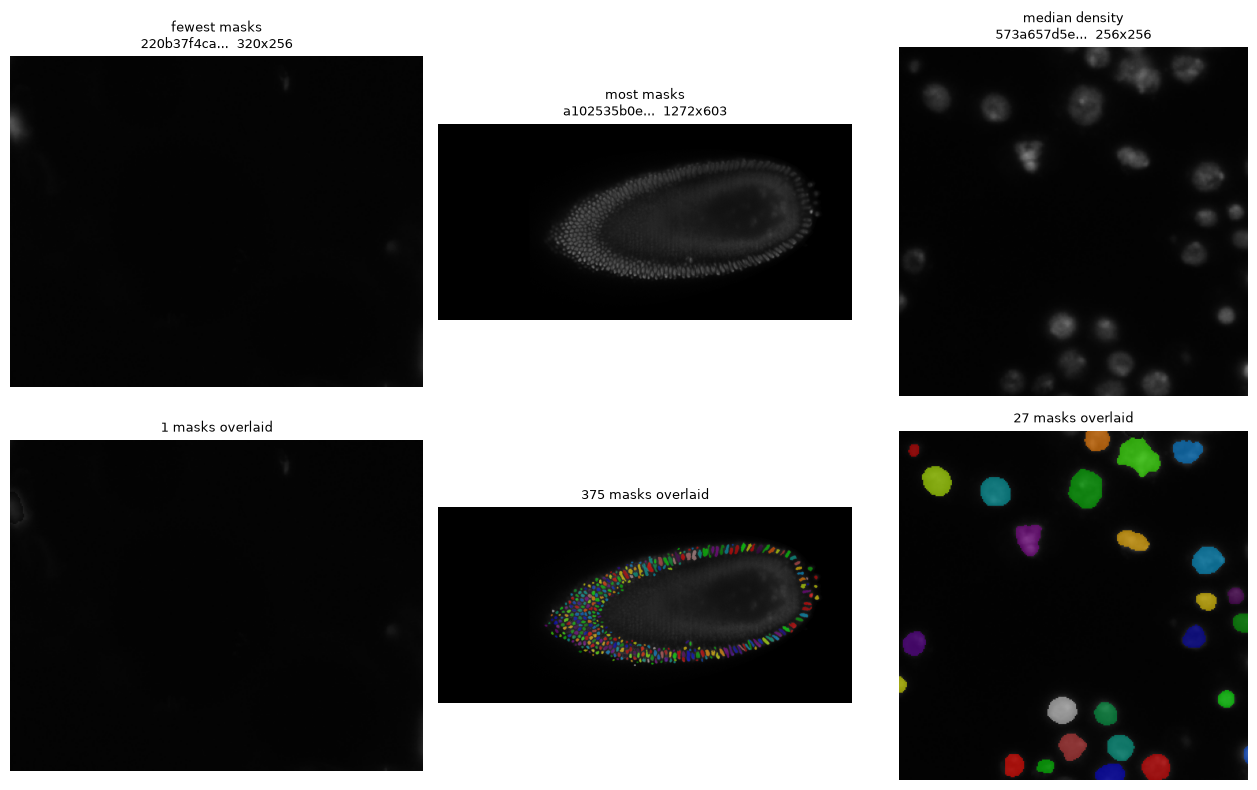

In [9]:
# === Visualize 3 diverse samples =============================================
# Picks exemplars straight from the audit report: sparsest, densest, and an
# anomalous sample (falls back to the median-density sample if none exist).
import cv2
import matplotlib.pyplot as plt
import numpy as np

counts = report["_mask_counts"]  # sample_id -> mask count


def pick_edge_case():
    """Return (sample_id, label) for the third panel."""
    if report["anomalies"]:
        a = report["anomalies"][0]
        return a["sample_id"], f"ANOMALY: {a['issue']}"
    # No defects -> show the median-density sample instead of an empty panel.
    # sorted(..., key=counts.get) orders ids by mask count; //2 takes the middle.
    ordered = sorted((k for k, v in counts.items() if v > 0), key=counts.get)
    return ordered[len(ordered) // 2], "median density"


picks = [
    (report["extremes"]["fewest"], "fewest masks"),
    (report["extremes"]["most"], "most masks"),
    pick_edge_case(),
]


def load_overlay(sample_id):
    """Decode image + flatten all masks into one 2-D label map."""
    sdir = TRAIN_DIR / sample_id
    img_path = next((sdir / "images").glob("*.png"), None)

    # IMREAD_COLOR drops the (constant-255) alpha channel for free; cv2 decodes
    # as BGR, so cvtColor is mandatory or matplotlib shows red/blue swapped.
    img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Label map, not a binary union: each nucleus gets its own integer id so
    # touching instances stay visually distinct under a categorical colormap.
    # int32 is enough for ~375 max instances and 4x lighter than int64.
    labels = np.zeros(img.shape[:2], dtype=np.int32)
    mask_paths = sorted((sdir / "masks").glob("*.png"))
    for i, mp in enumerate(mask_paths, start=1):
        m = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
        if m is None or m.shape != labels.shape:
            continue  # skip defects the audit already recorded
        # Boolean-mask assignment: labels[bool_array] = i writes ONLY the True
        # pixels in one vectorized C pass - no Python loop over pixels.
        labels[m > 127] = i
    return img, labels, len(mask_paths)


fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for col, (sid, label) in enumerate(picks):
    img, labels, n = load_overlay(sid)

    axes[0, col].imshow(img)
    axes[0, col].set_title(f"{label}\n{sid[:10]}...  {img.shape[1]}x{img.shape[0]}", fontsize=9)

    # np.ma.masked_where hides background (0) so the raw image shows through the
    # overlay; 'nipy_spectral' is cyclic-ish, giving neighbours contrasting hues.
    axes[1, col].imshow(img)
    axes[1, col].imshow(np.ma.masked_where(labels == 0, labels), cmap="nipy_spectral", alpha=0.6)
    axes[1, col].set_title(f"{n} masks overlaid", fontsize=9)

for ax in axes.ravel():
    ax.axis("off")  # pixel coordinates carry no meaning here

plt.tight_layout()
plt.show()

In [10]:
# === Deep profile: dimensions + fg/bg intensity ==============================
# Single disk pass (~29.5k mask decodes). Returns 670 scalar records, no arrays.
from src.dataset_audit import profile_dataset

prof = profile_dataset(str(TRAIN_DIR))
dims, inten = prof["dimensions"], prof["intensity"]

# --- 1. Resolution profile ---------------------------------------------------
print(f"modal resolution : {dims['modal']}  n={dims['modal_count']}  ({dims['modal_pct']}%)")
print(f"unique resolutions: {dims['unique_count']}")
print(f"deviant samples   : {dims['deviant_sample_count']}  ({dims['deviant_pct']}%)\n")

print(f"{'(H, W)':<16}{'count':>7}{'pct':>8}   flag")
for r in dims["distribution"]:
    flag = "DEVIANT" if r["deviant"] else "<- modal"
    print(f"{str(r['hw']):<16}{r['count']:>7}{r['pct']:>7.2f}%   {flag}")

a = dims["aspect"]
print(f"\naspect (w/h)     : min={a['min']}  max={a['max']}  mean={a['mean']}")
print(f"distinct aspects : {a['unique']}")
print(f"channel histogram: {dims['channel_hist']}  (4 = RGBA)")

# --- 2. Intensity / modality profile ----------------------------------------
print(f"\nbg_mean  : {inten['bg_mean']}")
print(f"fg_mean  : {inten['fg_mean']}")
print(f"delta    : {inten['contrast_delta']}")
print(f"modality : {inten['modality_hist']}")
print(f"inverted contrast (fg < bg) : {inten['inverted_contrast_count']}")
print(f"low separation (|delta|<20) : {inten['low_separation_count']}")
print(f"fg pixel fraction           : {inten['fg_fraction']}")

modal resolution : (256, 256)  n=334  (49.85%)
unique resolutions: 9
deviant samples   : 336  (50.15%)

(H, W)            count     pct   flag
(256, 256)          334  49.85%   <- modal
(256, 320)          112  16.72%   DEVIANT
(520, 696)           92  13.73%   DEVIANT
(360, 360)           91  13.58%   DEVIANT
(1024, 1024)         16   2.39%   DEVIANT
(512, 640)           13   1.94%   DEVIANT
(603, 1272)           6   0.90%   DEVIANT
(260, 347)            5   0.75%   DEVIANT
(1040, 1388)          1   0.15%   DEVIANT

aspect (w/h)     : min=1.0  max=2.11  mean=1.11
distinct aspects : [1.0, 1.25, 1.335, 1.338, 2.109]
channel histogram: {4: 670}  (4 = RGBA)

bg_mean  : {'min': 0.41, 'max': 219.09, 'mean': 40.56, 'median': 7.94, 'std': 67.5}
fg_mean  : {'min': 17.27, 'max': 187.25, 'mean': 65.88, 'median': 57.3, 'std': 34.91}
delta    : {'min': -123.53, 'max': 174.04, 'mean': 25.32, 'median': 35.6, 'std': 56.34}
modality : {'fluorescence': 546, 'brightfield': 124}
inverted contrast (fg < b

In [ ]:
# === Modality separation plots ===============================================
# Goal: prove the dataset is a MIXTURE of two acquisition modalities, which
# dictates whether per-modality normalization is required before modeling.
from scipy.stats import gaussian_kde

rows = prof["per_sample"]

# List comprehension -> np.array gives a contiguous float64 block; the `is not
# None` guard prevents an object-dtype array (whose .mean() would fail).
bg = np.array([r["bg_mean"] for r in rows if r["bg_mean"] is not None])
fg = np.array([r["fg_mean"] for r in rows if r["fg_mean"] is not None])
delta = np.array([r["contrast_delta"] for r in rows if r["contrast_delta"] is not None])
modality = np.array([r["modality"] for r in rows if r["contrast_delta"] is not None])

# Boolean mask over the record axis -> reusable row selector for every plot.
is_fluo = modality == "fluorescence"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# --- (a) dual histogram + KDE: background vs foreground ----------------------
grid = np.linspace(0, 255, 512)
for arr, color, name in [(bg, "tab:blue", "background"), (fg, "tab:orange", "foreground")]:
    ax[0].hist(arr, bins=48, range=(0, 255), alpha=0.4, color=color,
               density=True, label=f"{name} (hist)")
    # gaussian_kde smooths the discrete histogram into a continuous density.
    # It expects a (n_features, n_samples) layout; a 1-D array is accepted as-is.
    # Needs >1 distinct value, hence the size guard.
    if arr.size > 1:
        ax[0].plot(grid, gaussian_kde(arr)(grid), color=color, lw=2, label=f"{name} (KDE)")
ax[0].axvline(90, ls="--", c="k", lw=1, label="modality cut (bg=90)")
ax[0].set(xlabel="mean intensity (8-bit)", ylabel="density",
          title="(a) BG vs FG intensity - bimodality check")
ax[0].legend(fontsize=7)

# --- (b) scatter: bg vs fg per sample ----------------------------------------
# y == x line splits the plane: above = nuclei brighter than field, below =
# inverted contrast (stained nuclei on a bright field).
ax[1].plot([0, 255], [0, 255], ls="--", c="k", lw=1, label="fg = bg (no contrast)")
ax[1].scatter(bg[is_fluo], fg[is_fluo], s=14, alpha=0.6, c="tab:blue",
              label=f"fluorescence (n={is_fluo.sum()})")
ax[1].scatter(bg[~is_fluo], fg[~is_fluo], s=14, alpha=0.6, c="tab:red",
              label=f"brightfield (n={(~is_fluo).sum()})")
ax[1].set(xlabel="background mean", ylabel="foreground mean", xlim=(0, 255), ylim=(0, 255),
          title="(b) per-sample BG vs FG")
ax[1].legend(fontsize=7)

# --- (c) signed contrast delta ------------------------------------------------
ax[2].hist(delta[is_fluo], bins=40, alpha=0.6, color="tab:blue", label="fluorescence")
ax[2].hist(delta[~is_fluo], bins=40, alpha=0.6, color="tab:red", label="brightfield")
ax[2].axvline(0, ls="--", c="k", lw=1)
ax[2].set(xlabel="fg_mean - bg_mean", ylabel="samples",
          title="(c) signed contrast (left of 0 = inverted)")
ax[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

# --- resolution bar chart (log y: counts span 1 -> 334) ----------------------
fig, ax = plt.subplots(figsize=(9, 3.5))
labels = [f"{h}x{w}" for h, w in (r["hw"] for r in dims["distribution"])]
counts_d = [r["count"] for r in dims["distribution"]]
# Modal bar highlighted; the rest are resize/padding liabilities.
colors = ["tab:green" if not r["deviant"] else "tab:gray" for r in dims["distribution"]]
ax.bar(labels, counts_d, color=colors)
ax.set_yscale("log")
ax.set(ylabel="samples (log)", title="resolution distribution (green = modal)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()